# Actividad 2 — K-means (Notebook 2: avance con librerías)
**Asignatura:** Inteligencia Artificial I  
**Grupo:** 5  
**Estado:** Avance funcional para asesoría; **no es la entrega final**.

**Qué sí hace:** carga un dataset real, inspecciona los datos, los estandariza, ejecuta K-means con scikit-learn, muestra la inercia y representa los grupos en un gráfico.  
**Qué falta:** EDA profundo, comparación de valores de K, Silhouette Score, interpretación final y referencias IEEE.

## 1. Problema y datos
Queremos descubrir si las medidas físicas de las flores **Iris** forman grupos parecidos, **sin utilizar la etiqueta de especie durante el entrenamiento**.

Utilizaremos el conjunto de datos **Iris**, que contiene **150 observaciones** y **4 medidas numéricas**. Está incluido en scikit-learn: [documentación oficial](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_iris.html).

Con esto superamos el requisito de **al menos 100 registros para aprendizaje no supervisado**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Dataset integrado: se ejecuta sin subir archivos manualmente
iris = load_iris()
columnas = ['largo_sepalo', 'ancho_sepalo', 'largo_petalo', 'ancho_petalo']
df = pd.DataFrame(iris.data, columns=columnas)

print('Filas y columnas:', df.shape)
print('Valores nulos por columna:\n', df.isnull().sum())
print('Primeros registros:')
print(df.head())

Filas y columnas: (150, 4)
Valores nulos por columna:
 largo_sepalo    0
ancho_sepalo    0
largo_petalo    0
ancho_petalo    0
dtype: int64
Primeros registros:
   largo_sepalo  ancho_sepalo  largo_petalo  ancho_petalo
0           5.1           3.5           1.4           0.2
1           4.9           3.0           1.4           0.2
2           4.7           3.2           1.3           0.2
3           4.6           3.1           1.5           0.2
4           5.0           3.6           1.4           0.2


## 2. Exploración inicial
Revisamos un resumen estadístico antes de entrenar el modelo. Un análisis exploratorio más completo se agregará en otra versión.

In [2]:
print(df.describe().round(2))

# Guardar también una copia del dataset para la entrega futura
df.to_csv('Grupo5_Dataset_Iris.csv', index=False)
print('Dataset guardado como Grupo5_Dataset_Iris.csv')

       largo_sepalo  ancho_sepalo  largo_petalo  ancho_petalo
count        150.00        150.00        150.00        150.00
mean           5.84          3.06          3.76          1.20
std            0.83          0.44          1.77          0.76
min            4.30          2.00          1.00          0.10
25%            5.10          2.80          1.60          0.30
50%            5.80          3.00          4.35          1.30
75%            6.40          3.30          5.10          1.80
max            7.90          4.40          6.90          2.50
Dataset guardado como Grupo5_Dataset_Iris.csv


## 3. Preprocesamiento y entrenamiento inicial
Como las cuatro características tienen escalas diferentes, se estandarizan primero. K-means mide distancias, por eso la escala importa.

Por ahora usamos **K = 3** como primera prueba; todavía no hemos demostrado que sea la mejor cantidad de grupos.

In [3]:
escalador = StandardScaler()
X_escalado = escalador.fit_transform(df)

modelo = KMeans(n_clusters=3, random_state=42, n_init=10)
grupo = modelo.fit_predict(X_escalado)

df_resultados = df.copy()
df_resultados['grupo_kmeans'] = grupo

print('Cantidad de flores por grupo:')
print(df_resultados['grupo_kmeans'].value_counts().sort_index())
print('Inercia del modelo:', round(modelo.inertia_, 2))

Cantidad de flores por grupo:
grupo_kmeans
0    53
1    50
2    47
Name: count, dtype: int64
Inercia del modelo: 139.82


## 4. Primer gráfico de resultados
El modelo calcula los grupos usando **las cuatro variables estandarizadas**, pero aquí representamos **dos medidas** en un plano para verlos visualmente. Que algunos colores se superpongan en este plano no significa necesariamente que el modelo esté equivocado.

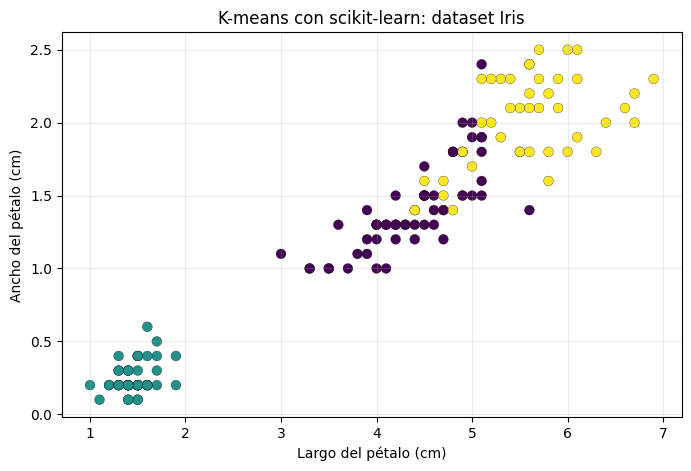

In [4]:
plt.figure(figsize=(8, 5))
plt.scatter(df['largo_petalo'], df['ancho_petalo'],
            c=grupo, cmap='viridis', s=50,
            edgecolors='black', linewidths=0.2)
plt.title('K-means con scikit-learn: dataset Iris')
plt.xlabel('Largo del pétalo (cm)')
plt.ylabel('Ancho del pétalo (cm)')
plt.grid(alpha=0.25)
plt.show()

## 5. Interpretación preliminar para presentar
El notebook carga 150 flores, verifica que no haya valores nulos, estandariza cuatro variables y utiliza la implementación de K-means de scikit-learn para generar tres grupos. Luego presenta un gráfico y la inercia del modelo.

La **inercia** resume la suma de distancias cuadradas de cada punto a su centroide. Un valor aislado no basta para decidir si los grupos son buenos: debe compararse con otros valores de K y otras métricas.

## 6. Pendiente para próximas versiones (no implementado todavía)
- [ ] Añadir histogramas, correlaciones y análisis de valores atípicos.
- [ ] Evaluar distintos K (método del codo) y calcular Silhouette Score.
- [ ] Profundizar en la interpretación, limitaciones y conclusiones.
- [ ] Añadir referencias completas en formato IEEE.

**Próximo commit sugerido:** `Evaluación con silhouette y selección de K`.